# 03 — Synthetic Traffic Generation
Generate scenario-driven synthetic snapshots with transparent dynamics and future travel-time targets.


## Scenario design
We create 60 scenarios across low/moderate/high demand, incidents, closures, congestion propagation, and recovery phases.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
PROC = PROJECT_ROOT / "data" / "processed"
SYN = PROJECT_ROOT / "data" / "synthetic"
SYN.mkdir(parents=True, exist_ok=True)

mapping = pd.read_csv(PROC / "road_segment_mapping.csv")
transitions = pd.read_csv(PROC / "segment_graph_edges.csv")
num_segments = len(mapping)
rng = np.random.default_rng(123)

num_scenarios = 60
num_snapshots = 2000
horizon_sec = 300


In [2]:
scenario_types = ["low", "moderate", "high", "incident", "closure", "recovery"]
scenario_meta = []
for sid in range(num_scenarios):
    stype = scenario_types[sid % len(scenario_types)]
    demand = {"low":0.35, "moderate":0.55, "high":0.75, "incident":0.65, "closure":0.6, "recovery":0.7}[stype]
    scenario_meta.append({"scenario_id":sid, "scenario_type":stype, "base_demand":demand})
scenario_meta = pd.DataFrame(scenario_meta)
scenario_meta.to_csv(SYN / "scenario_metadata.csv", index=False)
scenario_meta.head()


,scenario_id,scenario_type,base_demand
0,0,low,0.35
1,1,moderate,0.55
2,2,high,0.75
3,3,incident,0.65
4,4,closure,0.60


In [3]:
records = []
for snap in range(num_snapshots):
    scenario_id = int(snap % num_scenarios)
    meta = scenario_meta.iloc[scenario_id]
    t = snap * 30
    phase = 0.5 + 0.5 * np.sin(2*np.pi*(snap/96.0))
    base_density = np.clip(meta.base_demand * (0.7 + 0.6*phase), 0.1, 0.98)

    incident_mask = np.zeros(num_segments, dtype=np.float32)
    if meta.scenario_type in {"incident", "closure"}:
        center = (scenario_id * 7) % num_segments
        width = 8
        idx = np.arange(num_segments)
        incident_mask = np.exp(-((idx-center)**2)/(2*width**2))

    for i, row in mapping.iterrows():
        ff_speed = float(row["speed_kmh"])
        local = float(np.clip(base_density + 0.12*rng.normal() + 0.5*incident_mask[i], 0.02, 0.995))
        queue = max(0.0, (local - 0.6) * 18 + rng.normal(scale=0.7))

        closure_flag = 1 if (meta.scenario_type == "closure" and incident_mask[i] > 0.72) else 0
        capacity_factor = 0.2 if closure_flag else float(np.clip(1 - 0.65*incident_mask[i], 0.25, 1.0))

        current_speed = max(5.0, ff_speed * capacity_factor * (1 - local**1.4))
        length_km = float(row["length_m"]) / 1000.0
        current_tt = (length_km / max(current_speed, 1e-3)) * 3600.0

        future_density = np.clip(local + 0.08*np.sin(snap/12 + i/15) + 0.08*incident_mask[i], 0.02, 0.995)
        future_speed = max(4.0, ff_speed * capacity_factor * (1 - future_density**1.5))
        target_tt = (length_km / max(future_speed, 1e-3)) * 3600.0

        records.append({
            "snapshot_id": snap,
            "scenario_id": scenario_id,
            "simulation_run_id": scenario_id,
            "timestamp_sec": t,
            "road_segment_id": row["road_segment_id"],
            "current_speed_kmh": current_speed,
            "current_density": local,
            "queue_length": queue,
            "capacity_factor": capacity_factor,
            "closure_flag": closure_flag,
            "target_travel_time_sec": target_tt,
            "prediction_horizon_sec": horizon_sec,
            "provenance": "synthetic_v1",
        })

df = pd.DataFrame(records)
df.to_csv(SYN / "synthetic_snapshots.csv", index=False)
print("Saved rows:", len(df), "snapshots:", df.snapshot_id.nunique(), "scenarios:", df.scenario_id.nunique())


Saved rows: 626000 snapshots: 2000 scenarios: 60


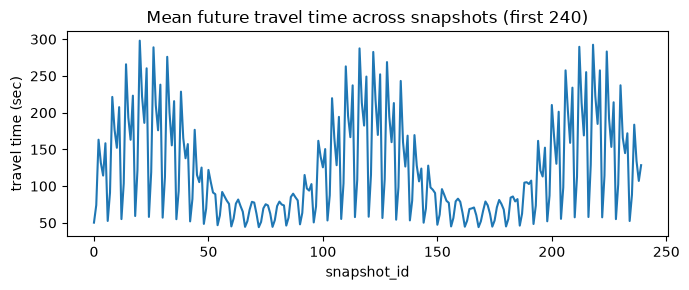

                           count        mean         std       min        25%  \
current_speed_kmh       626000.0   20.350915   11.065418  5.000000  11.493565   
current_density         626000.0    0.606531    0.218617  0.020000   0.446558   
queue_length            626000.0    1.708925    2.318591  0.000000   0.000000   
target_travel_time_sec  626000.0  112.765394  115.189319  7.656138  44.021140   

                              50%         75%         max  
current_speed_kmh       19.424396   27.766091   58.753229  
current_density          0.603583    0.771310    0.995000  
queue_length             0.072920    3.113157   10.050420  
target_travel_time_sec  72.454514  127.769015  807.300000  


In [4]:
sample = df.groupby("snapshot_id")["target_travel_time_sec"].mean().head(240)
plt.figure(figsize=(7,3))
plt.plot(sample.index, sample.values)
plt.title("Mean future travel time across snapshots (first 240)")
plt.xlabel("snapshot_id")
plt.ylabel("travel time (sec)")
plt.tight_layout()
plt.show()

print(df[["current_speed_kmh","current_density","queue_length","target_travel_time_sec"]].describe().T)


## Sanity checks summary
- Targets depend on current state + scenario dynamics + topology-linked perturbations.
- IDs are stable and persisted for downstream notebooks.
- Data is explicitly synthetic and not treated as calibrated real Bangalore traffic.
